# Señales crudas LAB013–015: CO₂, temperatura y química Y15

Visualización de solo lectura de los registros de `data/original/natural/lab013_015`: flujo de CO₂ crudo (`CO2_F*_LAB0*_SF.csv`), flujo de CO₂ filtrado (`CO2_FILT_F*_LAB0*.csv`), temperatura (`Temp_F*_LAB0*.csv`) y química offline del analizador Y15 (`Y15_LAB013-015.csv`). Sobre el filtrado se aplican la conversión histórica a g/L·h y la estimación del hueco a cero del sensor, con una figura por familia, un subgráfico por fermentador.
No se modifica ningún dato ni ningún otro notebook; las figuras quedan dentro del EXECUTED, sin exportar CSV ni PNG auxiliares.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/sources.csv').exists() and (p/'src').exists())
DATA=ROOT/'data/original/natural/lab013_015'
LABS=(('F1','LAB013'),('F2','LAB014'),('F3','LAB015'))
plt.rcParams.update({'figure.dpi':115,'font.family':'DejaVu Sans'})
def load(name):
    df=pd.read_csv(DATA/name,parse_dates=['timestamp'])
    df['t_h']=(df.timestamp-df.timestamp.iloc[0]).dt.total_seconds()/3600
    return df
SF={lab:load(f'CO2_{f}_{lab}_SF.csv') for f,lab in LABS}
FILT={lab:load(f'CO2_FILT_{f}_{lab}.csv') for f,lab in LABS}
TEMP={lab:load(f'Temp_{f}_{lab}.csv') for f,lab in LABS}
rows=[]
for f,lab in LABS:
    for familia,dfs,col in (('SF',SF,'flow_sccm'),('FILT',FILT,'flow_filt_sccm'),('Temp',TEMP,'T')):
        df=dfs[lab]
        row=dict(fermentador=f,lab=lab,familia=familia,n=len(df),inicio=df.timestamp.iloc[0],fin=df.timestamp.iloc[-1],minimo=float(df[col].min()),maximo=float(df[col].max()))
        if familia!='Temp':
            for k,v in df.status.value_counts().items():row[f'status_{k}']=int(v)
        rows.append(row)
display(pd.DataFrame(rows))

,fermentador,lab,familia,n,inicio,fin,minimo,maximo,status_OK,status_Bajo rango,status_Alto rango
0,F1,LAB013,SF,65590,2026-08-18 11:21:39,2026-08-26 10:00:37,0.0000,50.0000,58092.0,7458.0,40.0
1,F1,LAB013,FILT,65584,2026-08-18 11:22:30,2026-08-26 10:00:26,-0.1777,14.6643,58086.0,7458.0,40.0
2,F1,LAB013,Temp,193049,2026-08-18 11:20:36,2026-08-26 10:00:35,14.0000,17.5000,NaN,NaN,NaN
3,F2,LAB014,SF,65589,2026-08-18 11:21:49,2026-08-26 10:00:37,0.0000,50.0000,58210.0,7372.0,7.0
4,F2,LAB014,FILT,65583,2026-08-18 11:22:50,2026-08-26 10:00:37,-0.2354,17.2685,58204.0,7372.0,7.0
5,F2,LAB014,Temp,193046,2026-08-18 11:20:50,2026-08-26 10:00:40,13.8000,17.2000,NaN,NaN,NaN
6,F3,LAB015,SF,65587,2026-08-18 11:22:09,2026-08-26 10:00:37,0.0000,50.0000,58280.0,7285.0,22.0
7,F3,LAB015,FILT,65582,2026-08-18 11:23:01,2026-08-26 10:00:37,-0.2582,12.4157,58275.0,7285.0,22.0
8,F3,LAB015,Temp,193043,2026-08-18 11:21:05,2026-08-26 10:00:44,12.7000,17.5000,NaN,NaN,NaN


## CO₂ crudo (SF)

Salida directa del sensor de flujo másico, sin filtrar. La columna `status` distingue `OK`, `Bajo rango` (flujo nulo bajo el mínimo medible, dominante en las primeras horas) y `Alto rango` (saturación del sensor en 50 sccm); aquí se grafican todos los puntos tal cual.

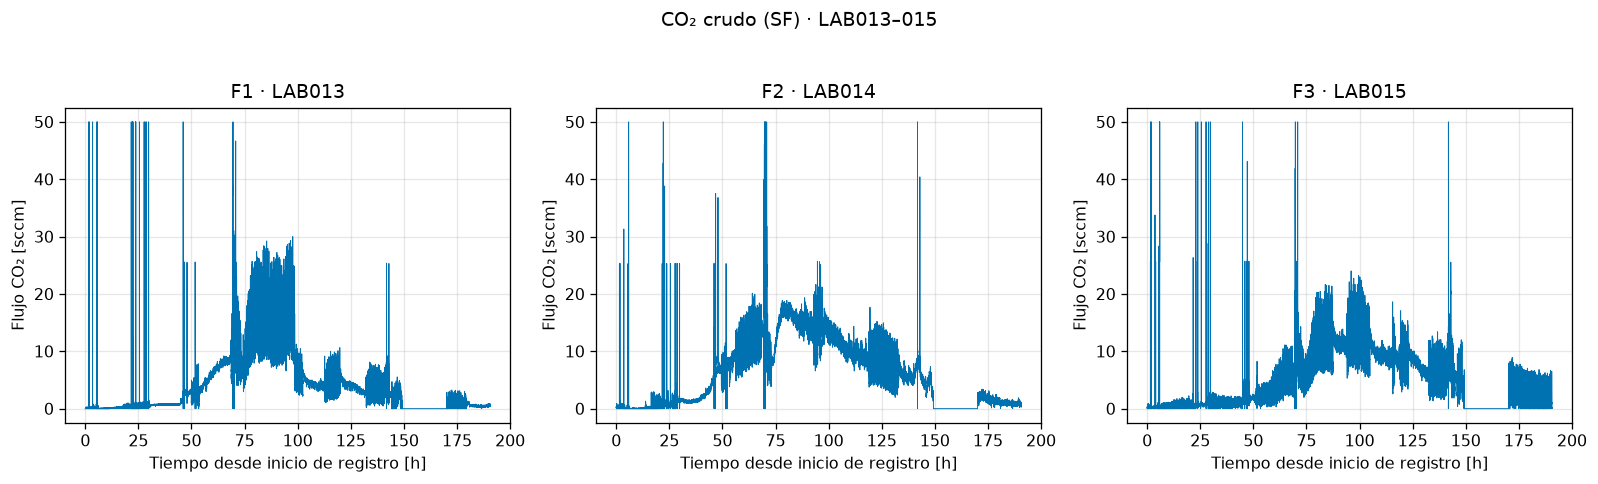

In [2]:
fig,axes=plt.subplots(1,3,figsize=(14,4),sharex=True)
for ax,(f,lab) in zip(axes,LABS):
    df=SF[lab]
    ax.plot(df.t_h,df.flow_sccm,color='#0072B2',lw=.6)
    ax.set_title(f'{f} · {lab}');ax.grid(alpha=.3)
    ax.set_xlabel('Tiempo desde inicio de registro [h]');ax.set_ylabel('Flujo CO₂ [sccm]')
fig.suptitle('CO₂ crudo (SF) · LAB013–015',y=1.04)
fig.tight_layout();plt.show()

## CO₂ filtrado (FILT)

Misma línea de tiempo que el crudo tras el preprocesado (columna `is_spike` marca outliers; no se grafica). Los picos de 50 sccm del crudo desaparecen y el rango útil baja a menos de 20 sccm. El tramo plano a cero hacia h ≈ 152–170 se estima en la sección del hueco.

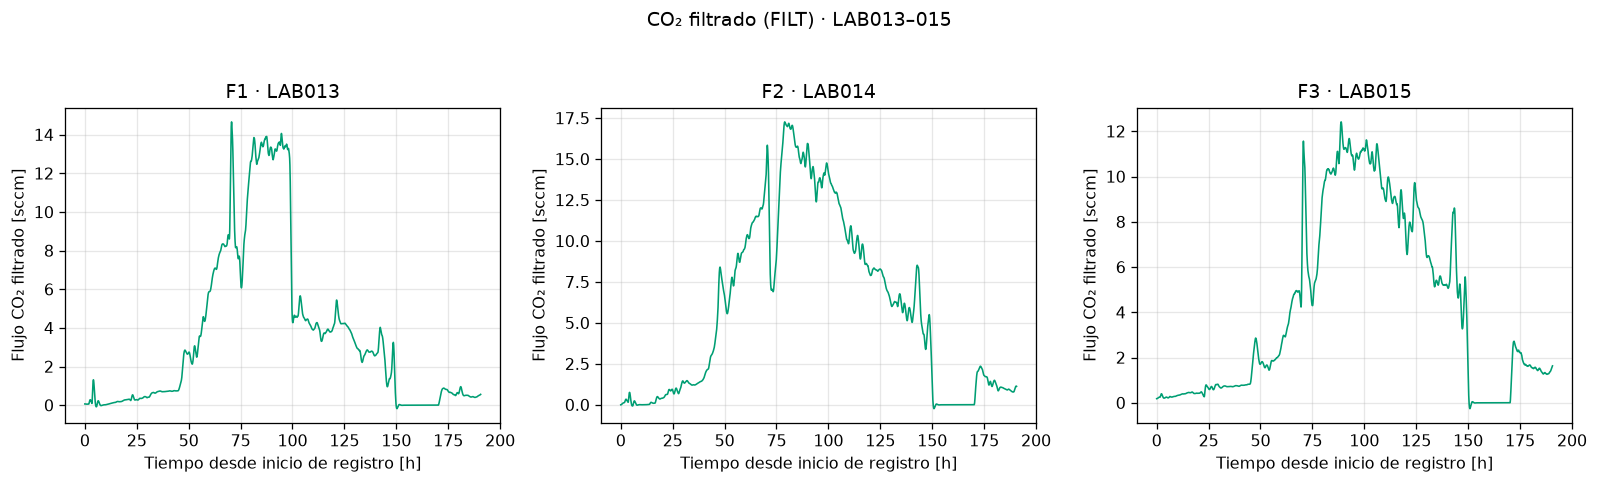

In [3]:
fig,axes=plt.subplots(1,3,figsize=(14,4),sharex=True)
for ax,(f,lab) in zip(axes,LABS):
    df=FILT[lab]
    ax.plot(df.t_h,df.flow_filt_sccm,color='#009E73',lw=1.0)
    ax.set_title(f'{f} · {lab}');ax.grid(alpha=.3)
    ax.set_xlabel('Tiempo desde inicio de registro [h]');ax.set_ylabel('Flujo CO₂ filtrado [sccm]')
fig.suptitle('CO₂ filtrado (FILT) · LAB013–015',y=1.04)
fig.tight_layout();plt.show()

## CO₂ filtrado convertido a g/L·h

Conversión histórica documentada en `notebooks/diagnostics/01_co2_mass_balance`: q = Q_sccm·M·60·0.74/(1000·24.16·2), con M = 44.0095 g/mol, volumen molar de referencia 24.16 L/mol, corrección de gas 0.74 y 2 L de volumen de líquido; equivale a multiplicar por ≈0.0404392 g/L·h por sccm.
2 L, 24.16 L/mol y 0.74 son supuestos heredados de la configuración GUI, no certificados del instrumento.

molar_mass_CO2_g_mol            44.009500
molar_volume_reference_L_mol    24.160000
gas_correction                   0.740000
volume_liquid_L                  2.000000
factor_g_l_h_per_sccm            0.040439
Name: Conversión histórica, dtype: float64

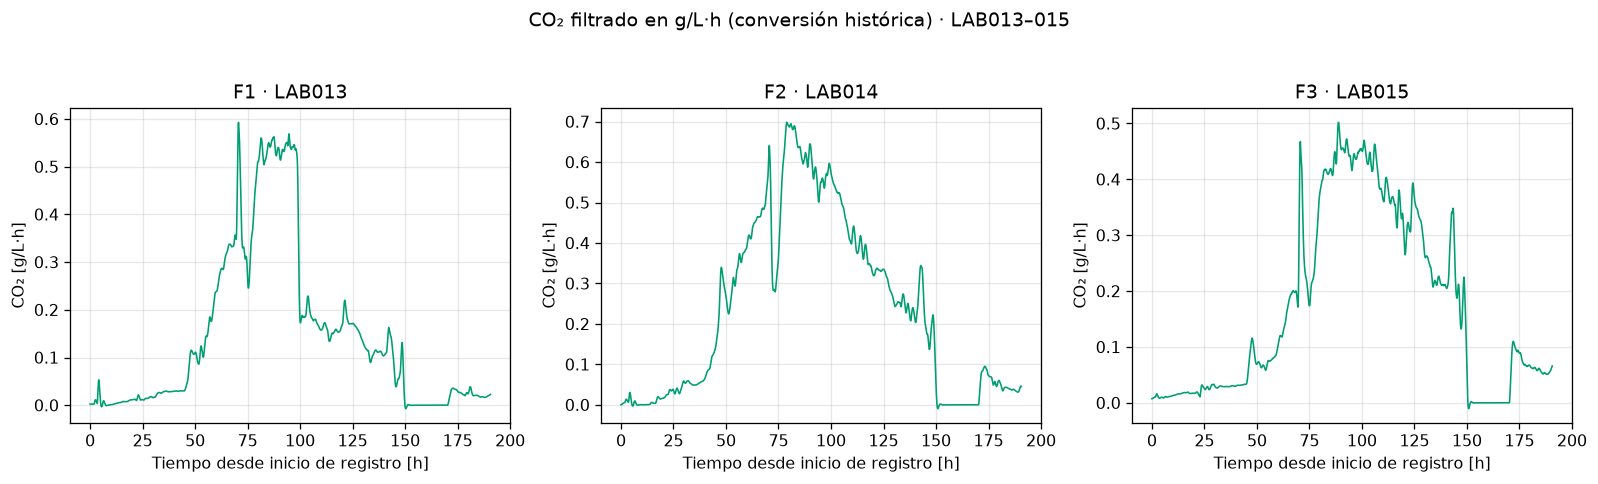

In [4]:
FACTOR=44.0095*60*.74/(1000*24.16*2)
display(pd.Series(dict(molar_mass_CO2_g_mol=44.0095,molar_volume_reference_L_mol=24.16,gas_correction=.74,volume_liquid_L=2.,factor_g_l_h_per_sccm=FACTOR),name='Conversión histórica'))
Q={lab:df.assign(q_g_l_h=df.flow_filt_sccm*FACTOR) for lab,df in FILT.items()}
fig,axes=plt.subplots(1,3,figsize=(14,4),sharex=True)
for ax,(f,lab) in zip(axes,LABS):
    df=Q[lab]
    ax.plot(df.t_h,df.q_g_l_h,color='#009E73',lw=1.0)
    ax.set_title(f'{f} · {lab}');ax.grid(alpha=.3)
    ax.set_xlabel('Tiempo desde inicio de registro [h]');ax.set_ylabel('CO₂ [g/L·h]')
fig.suptitle('CO₂ filtrado en g/L·h (conversión histórica) · LAB013–015',y=1.04)
fig.tight_layout();plt.show()

## Estimación del hueco a cero (~148–172 h)

Entre h ≈ 152 y h ≈ 170 las tres fermentaciones permanecen con `status` = `Bajo rango` (|q| < 0.01 sccm): el sensor dejó de capturar el valor real durante ~14–18 h, precedido por un colapso brusco desde el último nivel fiable y seguido por la reconexión en rampa.
El hueco se estima tratando todo ese tramo (último pico fiable → reconexión) como la interrupción de la medida: se detecta el último máximo local de la mediana móvil de 30 min antes del bajo rango (≈3.1–5.5 sccm) y el máximo de la rampa de reconexión (≈0.9–2.6 sccm), y entre ambos se tiende simplemente una recta.
Es una estimación, no un dato medido: supone que la caída a bajo rango forma parte del fallo de medida y que la producción real decayó suavemente entre ambos niveles; los datos por sí solos no permiten verificar si el descenso previo fue real.

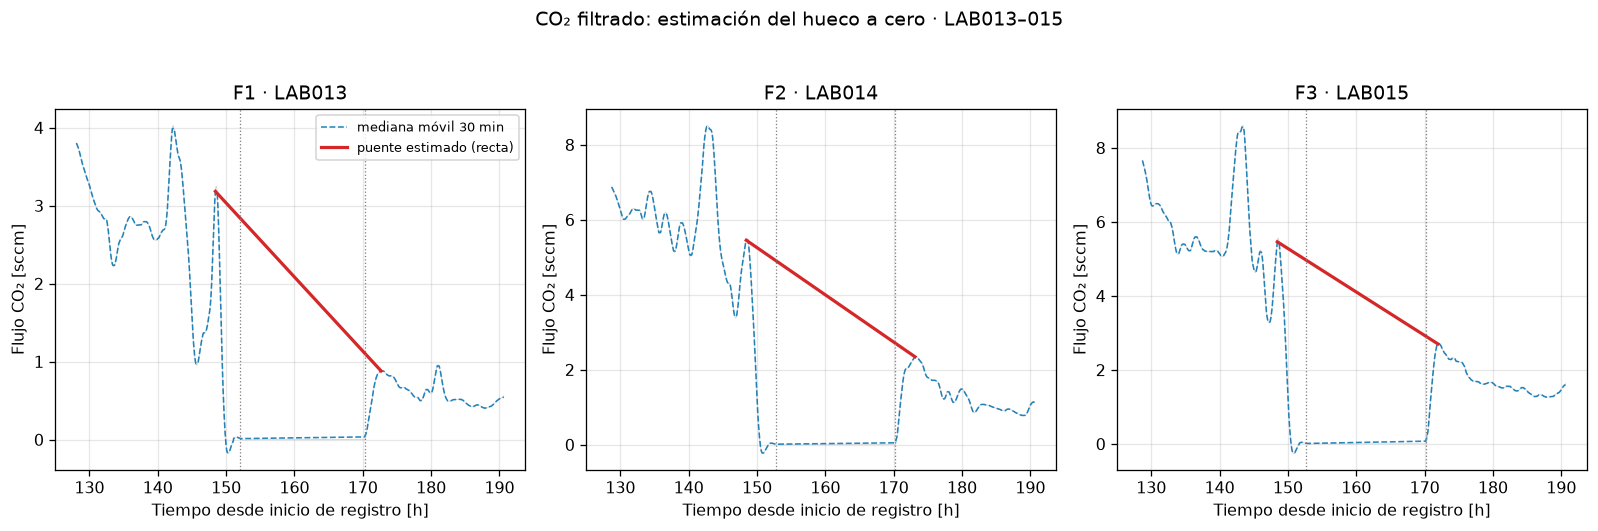

,fermentador,lab,bajo_rango_inicio_h,bajo_rango_fin_h,colapso_h,reconexion_h,nivel_colapso_sccm,nivel_reconexion_sccm,puente_media_sccm,puente_max_sccm
0,F1,LAB013,152.09,170.32,148.43,172.68,3.19,0.88,2.03,3.19
1,F2,LAB014,152.71,170.24,148.42,173.11,5.46,2.35,3.90,5.46
2,F3,LAB015,152.71,170.23,148.45,171.95,5.46,2.70,4.08,5.46


In [5]:
from scipy.interpolate import PchipInterpolator
def runs(mask):
    edges=np.diff(np.r_[False,mask.astype(bool),False].astype(int))
    return list(zip(np.flatnonzero(edges==1),np.flatnonzero(edges==-1)))
DEAD_MAX=.01;VENTANA=24.
rows=[];PUENTES={}
fig,axes=plt.subplots(1,3,figsize=(14,4.4),sharex=True)
for ax,(f,lab) in zip(axes,LABS):
    df=FILT[lab];t=df.t_h.to_numpy();y=df.flow_filt_sccm.to_numpy()
    dead=np.abs(y)<DEAD_MAX
    s,e=max(runs(dead),key=lambda r:r[1]-r[0]);d0,d1=t[s],t[e-1]
    serie=pd.Series(np.where(dead,np.nan,y),index=pd.to_timedelta(t,unit='h'))
    suave=serie.rolling('30min',center=True,min_periods=60).median().interpolate('index').to_numpy()
    left=(t>=d0-6)&(t<d0);right=(t>d1)&(t<=d1+6)
    t_left=float(t[left][np.argmax(suave[left])]);y_left=float(np.nanmax(suave[left]))
    t_right=float(t[right][np.argmax(suave[right])]);y_right=float(np.nanmax(suave[right]))
    tb=np.arange(t_left,t_right,1/60);bridge=y_left+(y_right-y_left)*(tb-t_left)/(t_right-t_left)
    PUENTES[lab]=pd.DataFrame(dict(t_h=tb,flow_sccm=bridge))
    rows.append(dict(fermentador=f,lab=lab,bajo_rango_inicio_h=round(d0,2),bajo_rango_fin_h=round(d1,2),
        colapso_h=round(t_left,2),reconexion_h=round(t_right,2),
        nivel_colapso_sccm=round(y_left,2),nivel_reconexion_sccm=round(y_right,2),
        puente_media_sccm=round(float(bridge.mean()),2),puente_max_sccm=round(float(bridge.max()),2)))
    w=(t>d0-VENTANA)&(t<d1+VENTANA)
    ax.plot(t[w],y[w],color='lightgray',lw=.5)
    ax.plot(t[w],suave[w],color='#0072B2',lw=1.,ls='--',alpha=.85,label='mediana móvil 30 min')
    ax.plot(tb,bridge,color='#D62728',lw=2,label='puente estimado (recta)')
    for x in (d0,d1):ax.axvline(x,color='gray',ls=':',lw=.8)
    ax.set_title(f'{f} · {lab}');ax.grid(alpha=.3)
    ax.set_xlabel('Tiempo desde inicio de registro [h]');ax.set_ylabel('Flujo CO₂ [sccm]')
axes[0].legend(loc='upper right',fontsize=8)
fig.suptitle('CO₂ filtrado: estimación del hueco a cero · LAB013–015',y=1.04)
fig.tight_layout();plt.show()
display(pd.DataFrame(rows))

## CO₂ filtrado corregido (sin conversión) y exportación

Se reemplaza el tramo de la interrupción (del último pico fiable a la reconexión, sección anterior) por la recta estimada, y el resto queda idéntico al registro FILT. La figura muestra la serie corregida como una sola línea verde, en sccm, sin la conversión a g/L·h.
La corrección se exporta a un CSV por fermentador en `results/` (`CO2_FILT_F*_LAB0*_corrected.csv`), con el mismo esquema del archivo original más la columna `is_estimated` (1 = muestra bajo la recta estimada, 0 = dato original). No se modifica ningún archivo de `data/`.

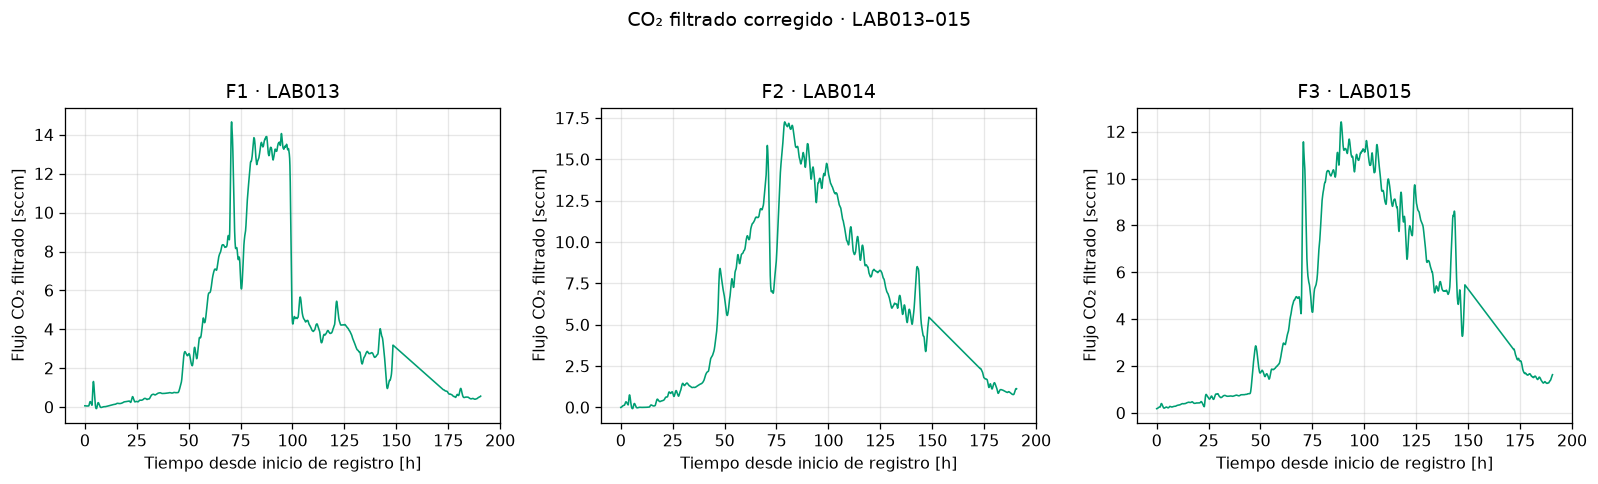

,fermentador,lab,muestras_estimadas,archivo
0,F1,LAB013,8398,results\CO2_FILT_F1_LAB013_corrected.csv
1,F2,LAB014,8548,results\CO2_FILT_F2_LAB014_corrected.csv
2,F3,LAB015,8139,results\CO2_FILT_F3_LAB015_corrected.csv


In [6]:
SALIDA=ROOT/'results'
rows=[];CORREGIDOS={}
fig,axes=plt.subplots(1,3,figsize=(14,4),sharex=True)
for ax,(f,lab) in zip(axes,LABS):
    df=FILT[lab].copy();puente=PUENTES[lab]
    est=((df.t_h>=puente.t_h.iloc[0])&(df.t_h<=puente.t_h.iloc[-1])).to_numpy()
    df['flow_filt_sccm']=np.where(est,np.interp(df.t_h,puente.t_h,puente.flow_sccm),df.flow_filt_sccm)
    df['is_estimated']=est.astype(int)
    destino=SALIDA/f'CO2_FILT_{f}_{lab}_corrected.csv'
    df.drop(columns='t_h').to_csv(destino,index=False,float_format='%.4f')
    CORREGIDOS[lab]=df
    rows.append(dict(fermentador=f,lab=lab,muestras_estimadas=int(est.sum()),archivo=str(destino.relative_to(ROOT))))
    ax.plot(df.t_h,df.flow_filt_sccm,color='#009E73',lw=1.0)
    ax.set_title(f'{f} · {lab}');ax.grid(alpha=.3)
    ax.set_xlabel('Tiempo desde inicio de registro [h]');ax.set_ylabel('Flujo CO₂ filtrado [sccm]')
fig.suptitle('CO₂ filtrado corregido · LAB013–015',y=1.04)
fig.tight_layout();plt.show()
display(pd.DataFrame(rows))

## Temperatura

Registro del controlador: temperatura medida `T` (línea llena) y consigna `SP` (línea punteada), a ~4 s frente a los 10 s del CO₂. El perfil corresponde a fermentación en frío con subida progresiva.

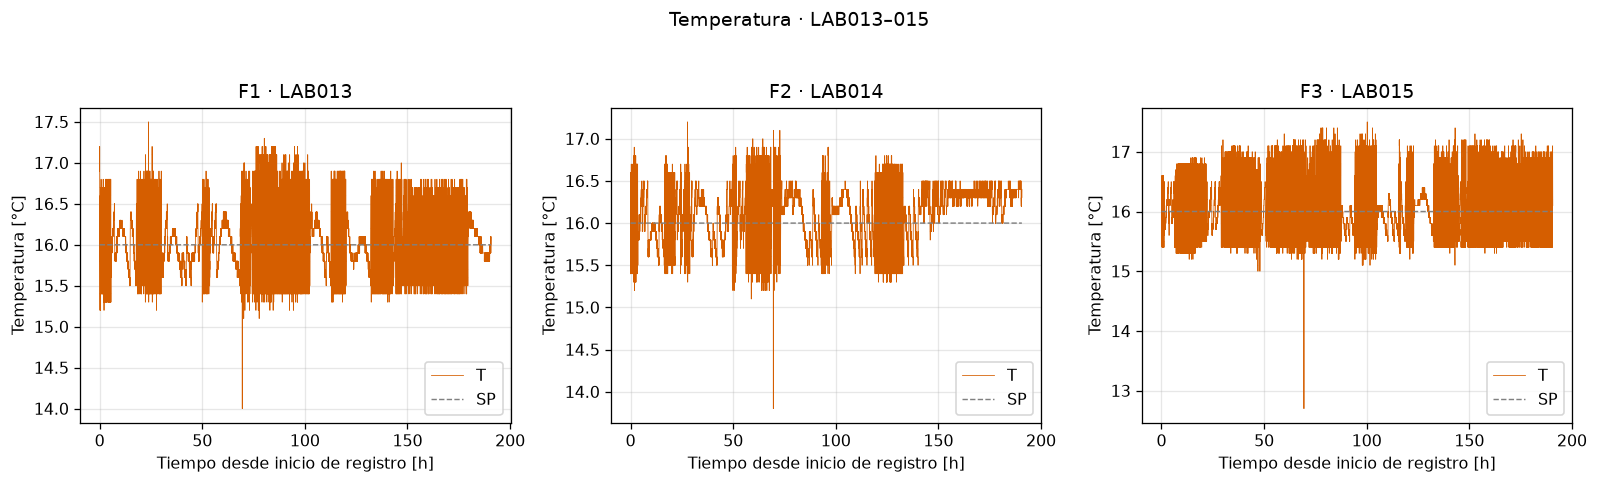

In [7]:
fig,axes=plt.subplots(1,3,figsize=(14,4),sharex=True)
for ax,(f,lab) in zip(axes,LABS):
    df=TEMP[lab]
    ax.plot(df.t_h,df['T'],color='#D55E00',lw=.5,label='T')
    ax.plot(df.t_h,df.SP,color='gray',lw=.9,ls='--',label='SP')
    ax.set_title(f'{f} · {lab}');ax.grid(alpha=.3)
    ax.set_xlabel('Tiempo desde inicio de registro [h]');ax.set_ylabel('Temperatura [°C]')
    ax.legend(loc='lower right')
fig.suptitle('Temperatura · LAB013–015',y=1.04)
fig.tight_layout();plt.show()

## Química offline (analizador Y15)

`Y15_LAB013-015.csv` concentra 8 muestras por fermentador (pre-inóculo más 7 de fermentación, 18–20 ago 2026: solo las primeras ~52 h) con siete analitos: YAN, amonio y PAN en mg N/L, y glucosa, fructosa, glucosa+fructosa y glicerol en g/L.
Tendencias visibles: el YAN cae de ~249 a ~150 mg/L, la glucosa de ~76 a ~60 g/L (consumo aún lento en esta etapa) y el glicerol sube de ~1.1 a ~2.4 g/L.
`Y15_LAB013-015.txt` es el volcado crudo del equipo: un panel de mosto (ST1, 14-08) con analitos adicionales (antocianos, IPT, acidez, SO₂, ácido acético, ICM) y filas sueltas de SO₂ libre en la muestra 7; esos analitos extra no tienen tabla por muestra en el CSV.
El eje temporal es horas desde la muestra de pre-inóculo de cada lab (los tres se sembraron con menos de 4 min de diferencia).

,sample_id,lab_id,fermenter,sample_type,y15_datetime,YAN_mg_L,ammonia_mg_L,PAN_mg_L,glucose_g_L,glucose_fructose_g_L,fructose_g_L,glycerol_g_L,t_h
0,LAB013-PI,LAB013,F1,pre_inoculum,2026-08-18 11:05:18,249.0,170.0,110.0,75.62,154.65,79.03,1.15,0.000000
1,LAB013-2,LAB013,F1,fermentation_sample,2026-08-18 13:12:58,237.0,164.0,102.0,71.13,146.60,75.47,1.13,2.127778
2,LAB013-3,LAB013,F1,fermentation_sample,2026-08-18 15:02:13,246.0,168.0,109.0,75.31,153.13,77.82,1.30,3.948611
3,LAB013-4,LAB013,F1,fermentation_sample,2026-08-18 17:10:13,245.0,167.0,108.0,75.06,154.55,79.49,1.12,6.081944
4,LAB013-5,LAB013,F1,fermentation_sample,2026-08-19 11:11:09,227.0,161.0,94.0,74.91,151.69,76.78,1.34,24.097500
5,LAB013-6,LAB013,F1,fermentation_sample,2026-08-19 15:32:51,207.0,150.0,84.0,65.18,139.09,73.91,1.52,28.459167
6,LAB013-7,LAB013,F1,fermentation_sample,2026-08-20 10:22:27,183.0,136.0,72.0,66.07,140.22,74.15,1.84,47.285833
7,LAB013-8,LAB013,F1,fermentation_sample,2026-08-20 15:37:23,164.0,122.0,64.0,61.99,134.95,72.96,2.16,52.534722
8,LAB014-PI,LAB014,F2,pre_inoculum,2026-08-18 11:06:06,247.0,170.0,107.0,76.54,156.92,80.38,1.12,0.000000
9,LAB014-2,LAB014,F2,fermentation_sample,2026-08-18 13:13:46,246.0,168.0,108.0,75.67,155.80,80.13,1.15,2.127778


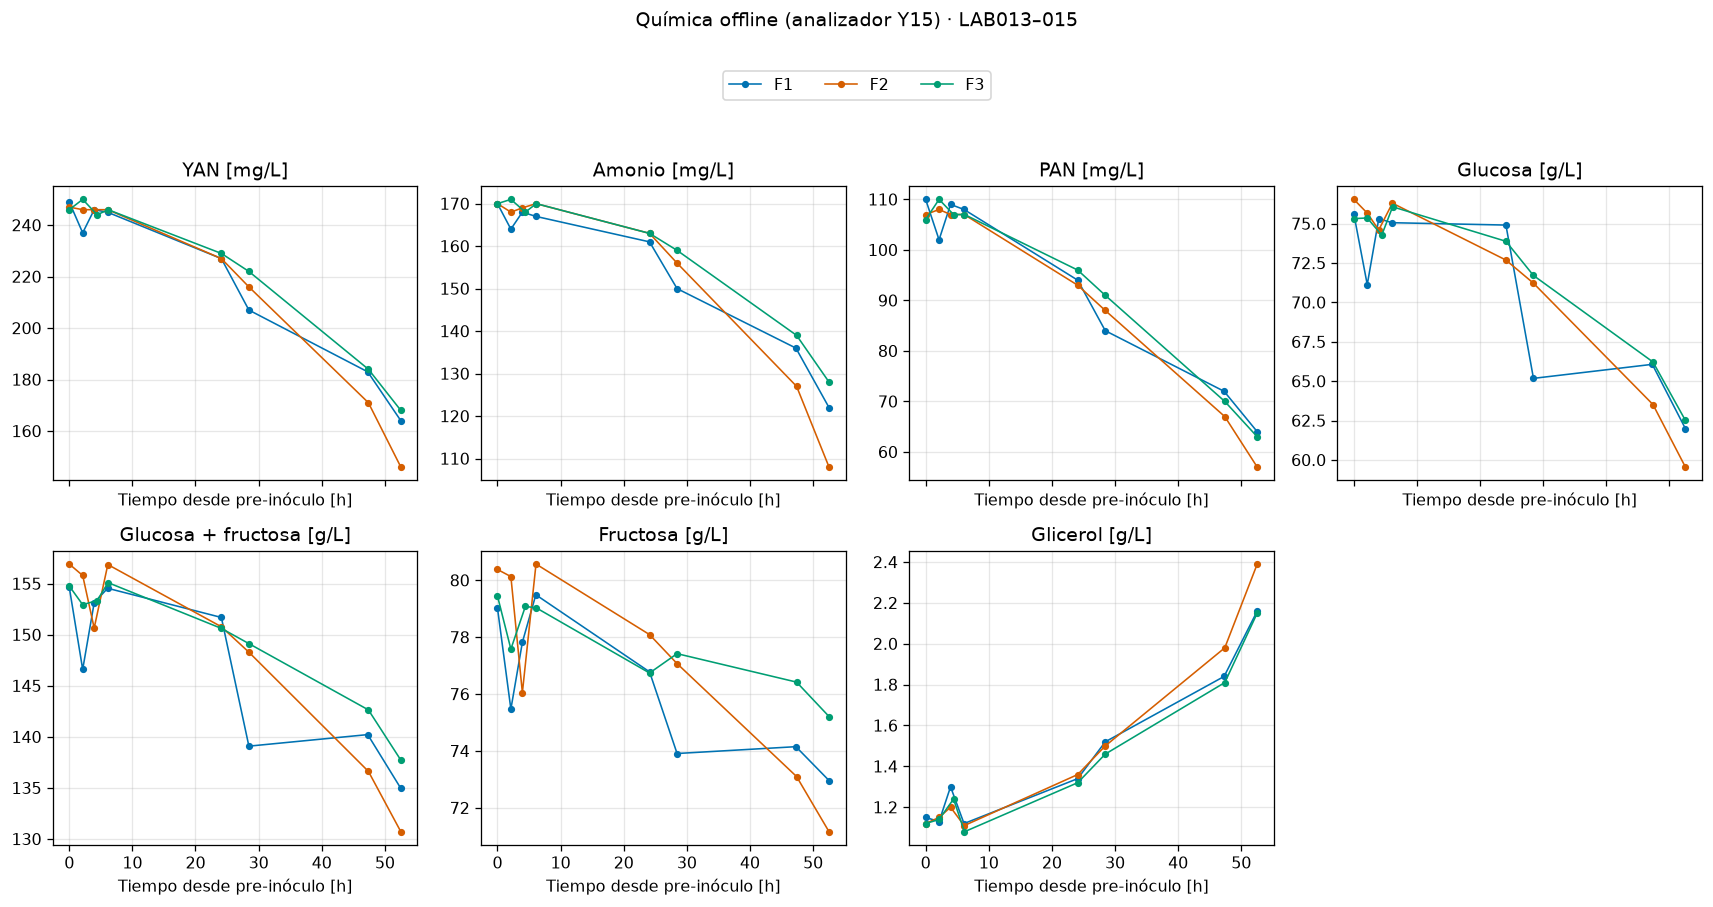

In [8]:
Y15=pd.read_csv(DATA/'Y15_LAB013-015.csv',parse_dates=['y15_datetime'])
Y15['t_h']=(Y15.y15_datetime-Y15.groupby('lab_id').y15_datetime.transform('first')).dt.total_seconds()/3600
display(Y15.drop(columns=['y15_datetime_end']))
ANALITOS=(('YAN_mg_L','YAN [mg/L]'),('ammonia_mg_L','Amonio [mg/L]'),('PAN_mg_L','PAN [mg/L]'),('glucose_g_L','Glucosa [g/L]'),('glucose_fructose_g_L','Glucosa + fructosa [g/L]'),('fructose_g_L','Fructosa [g/L]'),('glycerol_g_L','Glicerol [g/L]'))
COLORES={'F1':'#0072B2','F2':'#D55E00','F3':'#009E73'}
fig,axes=plt.subplots(2,4,figsize=(15,7),sharex=True)
for ax,(col,etq) in zip(axes.flat,ANALITOS):
    for f,lab in LABS:
        d=Y15[Y15.fermenter.eq(f)]
        ax.plot(d.t_h,d[col],marker='o',ms=3.5,lw=1,color=COLORES[f],label=f)
    ax.set_title(etq);ax.grid(alpha=.3);ax.set_xlabel('Tiempo desde pre-inóculo [h]')
axes.flat[-1].axis('off')
handles,labels=axes.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,1.055),ncol=3)
fig.suptitle('Química offline (analizador Y15) · LAB013–015',y=1.12)
fig.tight_layout();plt.show()